# EN4554 – Assignment 2: Convolutional Neural Networks

**Name:** *Pirathishanth*  
**Index number:** *220480P*  
**GitHub  :** https://github.com/pirathi2002/EN4554-Assignment-2-Convolutional-Neural-Networks

---

### Contents
| Part | Topic | Rough run time on a Colab T4 |
|---|---|---|
| Setup | Data, utilities | 1 min |
| Task 1 | Backpropagation from scratch (Linear / ReLU / softmax-CE), gradient checks, MLP training, vanishing gradients | ~5 min |
| Task 2 | Own SGD-momentum and Adam, behaviour on an ill-conditioned quadratic, optimiser / learning-rate sweep on a CNN | ~15 min |
| Task 3 | Regularisation study on 5k images; plain vs residual networks of depth 8 / 20 / 56 | ~60–90 min |
| Task 4 (optional) | Best CNN with ≤ 500k parameters and ≤ 20 epochs, ablation, one-shot test evaluation | ~30 min |

### Use of AI tools (required acknowledgement)
I used Claude (Anthropic) to help generate the initial code structure and the interpretation drafts of this notebook. I ran all the experiments myself on a Colab T4, checked the interpretations against my own results, and I understand the code.

In [22]:
import os, time, math, random, json, copy
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt

QUICK = False          # True -> tiny subsets + 1-2 epochs: a smoke test of the whole notebook
QUICK_N = (3000, 600)  # (#train, #val) used in QUICK mode
SEED = 42

def E(full, quick=1):
    """Number of epochs: `full` normally, `quick` in QUICK mode."""
    return quick if QUICK else full

def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

set_seed()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
print('torch', torch.__version__, '| device:', device, '| QUICK =', QUICK)

torch 2.11.0+cu130 | device: cuda | QUICK = False


## 0. Data: CIFAR-10, 45k / 5k split, per-channel normalisation

* The 50,000 official training images are split (fixed seed) into **45,000 train / 5,000 validation**.
* Each colour channel is normalised with the **mean / std of the 45k training images only** (no leakage from validation or test).
* The official 10,000-image **test set is not loaded here**; it is touched exactly once, at the very end of Task 4.
* The whole dataset is kept as tensors on the GPU, so training loops are fast and augmentation is done on the GPU as well.

train (45000, 3, 32, 32) | val (5000, 3, 32, 32)
channel mean [0.4917 0.4823 0.4467] | std [0.2471 0.2435 0.2616]
train class counts [4512, 4488, 4468, 4529, 4529, 4486, 4493, 4500, 4496, 4499]
val   class counts [488, 512, 532, 471, 471, 514, 507, 500, 504, 501]


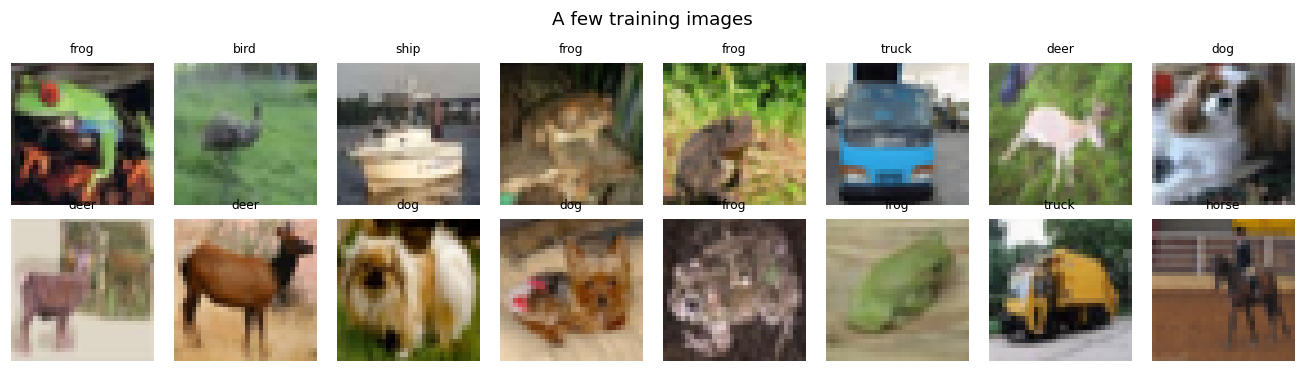

In [23]:
tv_train = torchvision.datasets.CIFAR10(root='./data', train=True, download=True)
CLASSES = tv_train.classes
X_u8 = torch.from_numpy(tv_train.data).permute(0, 3, 1, 2).contiguous()      # (50000,3,32,32) uint8
y_all = torch.tensor(tv_train.targets)

g = torch.Generator().manual_seed(SEED)
perm = torch.randperm(len(X_u8), generator=g)
tr_idx, va_idx = perm[:45000], perm[45000:]
if QUICK:
    tr_idx, va_idx = tr_idx[:QUICK_N[0]], va_idx[:QUICK_N[1]]

Xtr_raw = X_u8[tr_idx].float().div(255)
mean = Xtr_raw.mean((0, 2, 3), keepdim=True)          # per-channel statistics of the TRAINING split only
std  = Xtr_raw.std((0, 2, 3), keepdim=True)
Xtr = ((Xtr_raw - mean) / std).to(device); ytr = y_all[tr_idx].to(device)
Xva = ((X_u8[va_idx].float().div(255) - mean) / std).to(device); yva = y_all[va_idx].to(device)
del Xtr_raw
mean_d, std_d = mean.to(device), std.to(device)
def denorm(x): return (x * std_d + mean_d).clamp(0, 1)

print('train', tuple(Xtr.shape), '| val', tuple(Xva.shape))
print('channel mean', mean.flatten().numpy().round(4), '| std', std.flatten().numpy().round(4))
print('train class counts', torch.bincount(ytr.cpu(), minlength=10).tolist())
print('val   class counts', torch.bincount(yva.cpu(), minlength=10).tolist())

fig, ax = plt.subplots(2, 8, figsize=(12, 3.4))
for i, a in enumerate(ax.flat):
    a.imshow(denorm(Xtr[i:i+1])[0].permute(1, 2, 0).cpu()); a.set_title(CLASSES[ytr[i]], fontsize=8); a.axis('off')
plt.suptitle('A few training images'); plt.tight_layout(); plt.show()

## Shared utilities
`evaluate` (loss / accuracy in eval mode) and `train_model` (a generic training loop that supports GPU augmentation, mixup, label smoothing, a per-step LR scheduler, and records per-epoch curves). Everything later reuses these.

In [24]:
def count_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)

@torch.no_grad()
def evaluate(model, X, y, bs=1000):
    """Mean cross-entropy and accuracy of `model` (eval mode) on (X, y)."""
    was_training = model.training; model.eval()
    tot, ok = 0.0, 0
    for i in range(0, len(X), bs):
        out = model(X[i:i+bs])
        tot += F.cross_entropy(out, y[i:i+bs], reduction='sum').item()
        ok += (out.argmax(1) == y[i:i+bs]).sum().item()
    model.train(was_training)
    return tot / len(X), ok / len(X)

def warmup_cosine(opt, total_steps, warmup_steps=0):
    """Linear warm-up followed by cosine decay to 0; call .step() once per iteration."""
    def f(s):
        if s < warmup_steps: return (s + 1) / warmup_steps
        pr = (s - warmup_steps) / max(1, total_steps - warmup_steps)
        return 0.5 * (1 + math.cos(math.pi * pr))
    return torch.optim.lr_scheduler.LambdaLR(opt, f)

def train_model(model, opt, epochs, Xt, yt, Xv, yv, bs=128, augment=None, mixup_alpha=0.0,
                scheduler=None, label_smoothing=0.0, eval_train=False, tag='', log_every=None):
    """Generic training loop. Returns a dict of per-epoch curves.
    train_loss : running mean of the (possibly augmented / mixed) minibatch loss during the epoch
    train_acc  : accuracy on the CLEAN training set in eval mode if eval_train else running accuracy
    val_*      : clean validation loss / accuracy in eval mode
    """
    model.to(device)
    hist = {k: [] for k in ['train_loss', 'train_acc', 'val_loss', 'val_acc', 'time']}
    hist['diverged'] = False
    n = len(Xt); nb = n // bs                       # drop the last incomplete batch (a new shuffle each epoch)
    log_every = log_every or max(1, epochs // 5)
    t0 = time.time()
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(n, device=Xt.device)
        run_loss = torch.zeros((), device=Xt.device); run_ok = torch.zeros((), device=Xt.device)
        for k in range(nb):
            b = perm[k*bs:(k+1)*bs]
            xb, yb = Xt[b], yt[b]
            if augment is not None: xb = augment(xb)
            if mixup_alpha > 0:                     # mixup: convex combination of two minibatches / label sets
                lam = float(np.random.beta(mixup_alpha, mixup_alpha))
                p = torch.randperm(len(xb), device=xb.device)
                out = model(lam * xb + (1 - lam) * xb[p])
                loss = lam * F.cross_entropy(out, yb, label_smoothing=label_smoothing) \
                     + (1 - lam) * F.cross_entropy(out, yb[p], label_smoothing=label_smoothing)
            else:
                out = model(xb)
                loss = F.cross_entropy(out, yb, label_smoothing=label_smoothing)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            if scheduler is not None: scheduler.step()
            run_loss += loss.detach() * len(b); run_ok += (out.argmax(1) == yb).sum()
        tl = run_loss.item() / (nb * bs)
        ta = evaluate(model, Xt, yt)[1] if eval_train else run_ok.item() / (nb * bs)
        vl, va = evaluate(model, Xv, yv)
        for k_, v_ in zip(['train_loss', 'train_acc', 'val_loss', 'val_acc', 'time'], [tl, ta, vl, va, time.time() - t0]):
            hist[k_].append(v_)
        if (ep + 1) % log_every == 0 or ep == 0 or ep == epochs - 1:
            print(f'[{tag}] ep {ep+1:3d}/{epochs} | train loss {tl:.3f} acc {ta:.3f} | val loss {vl:.3f} acc {va:.3f} | {time.time()-t0:5.0f}s')
        if not math.isfinite(tl):
            hist['diverged'] = True; print(f'[{tag}] diverged (loss = {tl}) - stopping early'); break
    return hist

# Task 1 – Backpropagation from scratch

## 1(a) Layers with explicit forward / backward (no autograd)

Notation: a layer receives the upstream gradient $\delta = \partial L/\partial y$ in `backward` and returns $\partial L/\partial x$; it stores whatever it needs from the forward pass.

| Layer | Forward | Backward |
|---|---|---|
| Linear | $y = xW + b$ | $\partial L/\partial W = x^\top\delta,\; \partial L/\partial b = \sum_n \delta_n,\; \partial L/\partial x = \delta W^\top$ |
| ReLU | $y=\max(0,x)$ | $\partial L/\partial x = \delta \odot \mathbb 1[x>0]$ |
| Sigmoid (used in 1(d)) | $y=\sigma(x)$ | $\partial L/\partial x = \delta \odot y(1-y)$ |
| Softmax + CE | $L=-\frac1N\sum_n \log \mathrm{softmax}(z_n)_{y_n}$ | $\partial L/\partial z = \frac1N(\mathrm{softmax}(z)-\mathrm{onehot}(y))$ |

The softmax cross-entropy is computed with the log-sum-exp trick for numerical stability.

In [25]:
class Linear:
    def __init__(self, din, dout, init='kaiming', dtype=torch.float32, dev='cpu', gen=None):
        # Kaiming-He: Var = 2/fan_in (suited to ReLU).  Xavier-Glorot: Var = 2/(fan_in+fan_out) (suited to sigmoid/tanh)
        std = math.sqrt(2.0 / din) if init == 'kaiming' else math.sqrt(2.0 / (din + dout))
        self.W = (torch.randn(din, dout, generator=gen, dtype=dtype) * std).to(dev)
        self.b = torch.zeros(dout, dtype=dtype, device=dev)
    def forward(self, x):
        self.x = x
        return x @ self.W + self.b
    def backward(self, dout):
        self.dW = self.x.T @ dout
        self.db = dout.sum(0)
        return dout @ self.W.T

class ReLU:
    def forward(self, x):
        self.mask = (x > 0).to(x.dtype)
        return x * self.mask
    def backward(self, dout):
        return dout * self.mask

class Sigmoid:
    def forward(self, x):
        self.y = torch.sigmoid(x)
        return self.y
    def backward(self, dout):
        return dout * self.y * (1 - self.y)

class SoftmaxCrossEntropy:
    def forward(self, logits, y):
        z = logits - logits.max(1, keepdim=True).values                 # shift for stability
        logp = z - torch.logsumexp(z, 1, keepdim=True)
        self.p, self.y = logp.exp(), y
        return -logp[torch.arange(len(y)), y].mean()
    def backward(self):
        g = self.p.clone()
        g[torch.arange(len(self.y)), self.y] -= 1
        return g / len(self.y)

ACTS = {'relu': ReLU, 'sigmoid': Sigmoid}

class MLP:
    """Linear -> act -> Linear -> act -> ... -> Linear  (logits). Manual backprop."""
    def __init__(self, sizes, act='relu', init='kaiming', dtype=torch.float32, dev='cpu', gen=None):
        self.layers = []
        for i, (a, b) in enumerate(zip(sizes[:-1], sizes[1:])):
            self.layers.append(Linear(a, b, init, dtype, dev, gen))
            if i < len(sizes) - 2: self.layers.append(ACTS[act]())
    def forward(self, x):
        for l in self.layers: x = l.forward(x)
        return x
    def backward(self, d):
        for l in reversed(self.layers): d = l.backward(d)
        return d
    def linears(self): return [l for l in self.layers if isinstance(l, Linear)]
    def sgd_step(self, lr):
        for l in self.linears():
            l.W -= lr * l.dW; l.b -= lr * l.db

print('layers defined')

layers defined


## 1(b) Gradient checking

A small MLP (3072-64-32-10, ReLU) is checked in **float64** on a batch of 16 images against

1. **autograd** (same weights, same loss expressed with `F.cross_entropy`) – *all* entries, using `torch.allclose`;
2. **centred finite differences** $\frac{L(\theta+\epsilon e_k)-L(\theta-\epsilon e_k)}{2\epsilon}$, $\epsilon=10^{-6}$ – on 30 randomly chosen entries of every parameter tensor (a full check of the 3072×64 matrix would need ~400k forward passes).

Relative error: $\;|a-b| / \max(|a|+|b|,\,\text{floor})$ (a small floor avoids dividing by ~0 for entries whose true gradient is 0).

In [26]:
set_seed()
dt = torch.float64
net = MLP([3072, 64, 32, 10], 'relu', 'kaiming', dtype=dt)            # CPU, float64
xb = Xtr[:16].reshape(16, -1).to('cpu', dt); yb = ytr[:16].cpu()
ce = SoftmaxCrossEntropy()
def loss_value(): return ce.forward(net.forward(xb), yb).item()

# ---- our analytic gradients
L0 = loss_value(); net.backward(ce.backward())
ana, params = {}, {}
for i, l in enumerate(net.linears(), 1):
    ana[f'W{i}'], ana[f'b{i}'] = l.dW.clone(), l.db.clone()
    params[f'W{i}'], params[f'b{i}'] = l.W, l.b

# ---- autograd reference with identical weights
ws = [(l.W.clone().requires_grad_(), l.b.clone().requires_grad_()) for l in net.linears()]
h = xb
for i, (W, b) in enumerate(ws):
    h = h @ W + b
    if i < len(ws) - 1: h = torch.relu(h)
L_ag = F.cross_entropy(h, yb); L_ag.backward()
auto = {}
for i, (W, b) in enumerate(ws, 1): auto[f'W{i}'], auto[f'b{i}'] = W.grad, b.grad
print(f'loss (ours) = {L0:.12f} | loss (autograd) = {L_ag.item():.12f}')

# ---- centred finite differences on random entries
eps, K = 1e-6, 30
rng = np.random.default_rng(SEED)
def fd_grad(p, k):
    flat = p.view(-1); old = flat[k].item()
    flat[k] = old + eps; lp = loss_value()
    flat[k] = old - eps; lm = loss_value()
    flat[k] = old
    return (lp - lm) / (2 * eps)

def rel_err(a, b, floor):
    return ((a - b).abs() / (a.abs() + b.abs()).clamp_min(floor)).max().item()

print(f"\n{'param':6s}{'shape':>14s}{'|grad|':>11s}  {'max rel.err vs autograd':>24s} {'allclose':>9s}  {'max rel.err vs FD':>18s} {'allclose':>9s}")
all_ok = True
for name in ana:
    p = params[name]
    ok_ag = torch.allclose(ana[name], auto[name], rtol=1e-7, atol=1e-10)
    ks = rng.choice(p.numel(), size=min(K, p.numel()), replace=False)
    fd = torch.tensor([fd_grad(p, k) for k in ks], dtype=dt)
    an = ana[name].reshape(-1)[ks]
    ok_fd = torch.allclose(fd, an, rtol=1e-4, atol=1e-7)
    all_ok &= ok_ag and ok_fd
    print(f'{name:6s}{str(tuple(p.shape)):>14s}{ana[name].norm().item():11.3e}  {rel_err(ana[name], auto[name], 1e-8):24.3e} {str(ok_ag):>9s}  {rel_err(an, fd, 1e-6):18.3e} {str(ok_fd):>9s}')
print('\nAll gradient checks passed:', all_ok)

loss (ours) = 2.825113705804 | loss (autograd) = 2.825113705804

param          shape     |grad|   max rel.err vs autograd  allclose   max rel.err vs FD  allclose
W1        (3072, 64)  1.108e+01                 9.828e-13      True           7.192e-08      True
b1             (64,)  3.104e-01                 2.012e-15      True           1.301e-07      True
W2          (64, 32)  1.996e+00                 7.149e-14      True           2.291e-07      True
b2             (32,)  3.484e-01                 4.407e-16      True           2.068e-07      True
W3          (32, 10)  1.957e+00                 1.534e-15      True           4.679e-08      True
b3             (10,)  3.558e-01                 3.227e-15      True           9.809e-08      True

All gradient checks passed: True


**Interpretation (1b).** The relative errors against autograd are between 1e-16 and 1e-12 for every parameter tensor, and `torch.allclose` is `True` everywhere, so the backward passes of Linear, ReLU and softmax-cross-entropy are correct. The errors against centred finite differences are larger (5e-8 to 2e-7). This is expected: the numerical derivative has a truncation error of order ε² and a round-off error of order u/ε, so with ε = 1e-6 it cannot be more accurate than about 1e-8, whereas autograd and our analytic formulas have no such limit. A centred difference is preferred to a one-sided one because its truncation error is O(ε²) instead of O(ε). The check is done in float64 on a small network and batch because float32 round-off (~1e-7) would swamp the finite-difference estimate. A ReLU network can occasionally fail the check when a pre-activation is within ε of the kink at 0, because the function is not differentiable there.

## 1(c) Train the hand-written MLP with SGD on flattened CIFAR-10

3072-512-256-10 ReLU MLP, Kaiming init, plain minibatch SGD (lr 0.05, batch 128) with our own forward/backward – no autograd anywhere in this cell.

epoch  1/20 | loss(last 100 it) 1.573 | train acc 0.505 | val acc 0.451 | 1s
epoch  2/20 | loss(last 100 it) 1.407 | train acc 0.559 | val acc 0.480 | 1s
epoch  3/20 | loss(last 100 it) 1.304 | train acc 0.605 | val acc 0.500 | 2s
epoch  4/20 | loss(last 100 it) 1.198 | train acc 0.647 | val acc 0.507 | 2s
epoch  5/20 | loss(last 100 it) 1.127 | train acc 0.672 | val acc 0.504 | 3s
epoch  6/20 | loss(last 100 it) 1.043 | train acc 0.704 | val acc 0.513 | 3s
epoch  7/20 | loss(last 100 it) 0.956 | train acc 0.733 | val acc 0.518 | 4s
epoch  8/20 | loss(last 100 it) 0.899 | train acc 0.750 | val acc 0.511 | 4s
epoch  9/20 | loss(last 100 it) 0.845 | train acc 0.738 | val acc 0.479 | 5s
epoch 10/20 | loss(last 100 it) 0.777 | train acc 0.776 | val acc 0.491 | 5s
epoch 11/20 | loss(last 100 it) 0.712 | train acc 0.805 | val acc 0.497 | 6s
epoch 12/20 | loss(last 100 it) 0.659 | train acc 0.834 | val acc 0.518 | 6s
epoch 13/20 | loss(last 100 it) 0.606 | train acc 0.850 | val acc 0.505 | 7s

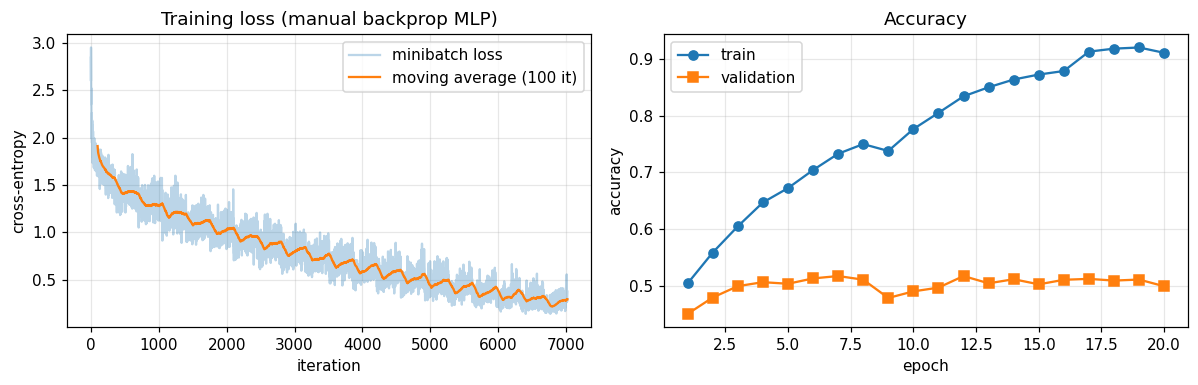

FINAL  train acc 0.9105 | validation acc 0.4996 (best 0.5176)


In [27]:
set_seed()
Xtr_f, Xva_f = Xtr.reshape(len(Xtr), -1), Xva.reshape(len(Xva), -1)
mlp = MLP([3072, 512, 256, 10], 'relu', 'kaiming', dev=device)
ce = SoftmaxCrossEntropy()
lr, bs, epochs = 0.05, 128, E(20, 2)
step_losses, tr_accs, va_accs = [], [], []
t0 = time.time()
for ep in range(epochs):
    perm = torch.randperm(len(Xtr_f), device=device)
    for k in range(len(Xtr_f) // bs):
        b = perm[k*bs:(k+1)*bs]
        loss = ce.forward(mlp.forward(Xtr_f[b]), ytr[b])
        mlp.backward(ce.backward())
        mlp.sgd_step(lr)
        step_losses.append(loss.item())
    tr_accs.append((mlp.forward(Xtr_f).argmax(1) == ytr).float().mean().item())
    va_accs.append((mlp.forward(Xva_f).argmax(1) == yva).float().mean().item())
    print(f'epoch {ep+1:2d}/{epochs} | loss(last 100 it) {np.mean(step_losses[-100:]):.3f} | train acc {tr_accs[-1]:.3f} | val acc {va_accs[-1]:.3f} | {time.time()-t0:.0f}s')

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ma = np.convolve(step_losses, np.ones(100) / 100, mode='valid')
ax[0].plot(step_losses, alpha=0.3, label='minibatch loss'); ax[0].plot(np.arange(len(ma)) + 99, ma, label='moving average (100 it)')
ax[0].set_xlabel('iteration'); ax[0].set_ylabel('cross-entropy'); ax[0].set_title('Training loss (manual backprop MLP)'); ax[0].legend()
ax[1].plot(range(1, epochs + 1), tr_accs, 'o-', label='train'); ax[1].plot(range(1, epochs + 1), va_accs, 's-', label='validation')
ax[1].set_xlabel('epoch'); ax[1].set_ylabel('accuracy'); ax[1].set_title('Accuracy'); ax[1].legend()
plt.tight_layout(); plt.show()
print(f'FINAL  train acc {tr_accs[-1]:.4f} | validation acc {va_accs[-1]:.4f} (best {max(va_accs):.4f})')

**Interpretation (1c).** The training loss falls steadily from about 1.57 in the first epoch to 0.30 after 20 epochs and has not flattened, while training accuracy rises to 91%. Validation accuracy, however, stalls at about 50% (best 51.8%, final 50.0%) from roughly epoch 3 onwards, so a large train–validation gap of about 41 points opens up. The 1.7M-parameter MLP simply memorises the training images. An MLP treats the image as a flat vector, with no weight sharing or translation equivariance, so it cannot exploit the spatial structure of the images and generalises poorly. A CNN of far fewer parameters should reach well above 70% on the same data (see Task 2c and 3b).

## 1(d) Per-layer gradient norms at initialisation: sigmoid vs ReLU

A **10-layer MLP** (3072 → 256 × 9 → 10, i.e. 10 linear layers) is built with our own layers. At initialisation we do one forward/backward pass on a batch of 256 images and record $\|\partial L/\partial W_\ell\|_F$ for every layer $\ell$.
We use the init that is *standard* for each non-linearity (Xavier for sigmoid, Kaiming for ReLU) and, for completeness, also the mismatched combinations. Because the first and last layers have different shapes, the right panel shows the RMS gradient per weight ($\|g\|_F/\sqrt{\#\text{params}}$), which is comparable across layers.

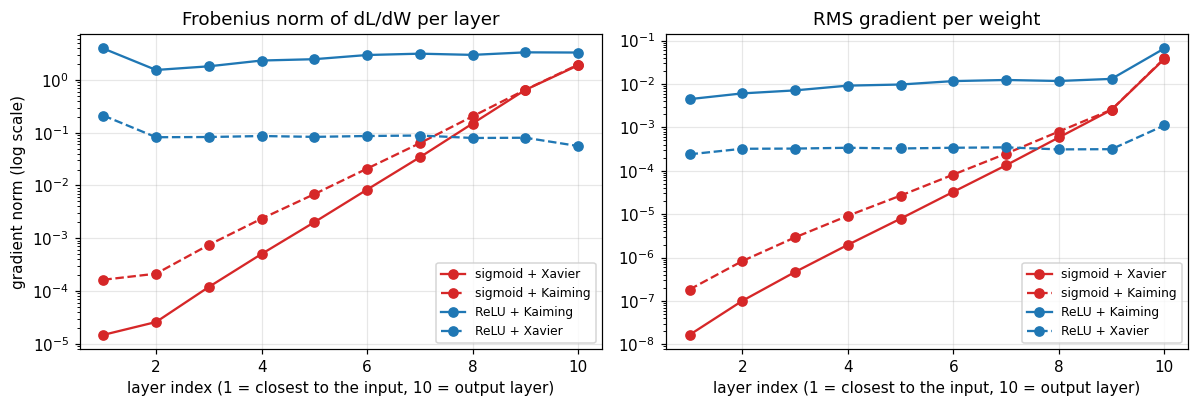

sigmoid + Xavier   grad-norm layer1 / layer10 = 7.735e-06   (layer 1: 1.47e-05, layer 10: 1.90e+00)
sigmoid + Kaiming  grad-norm layer1 / layer10 = 8.324e-05   (layer 1: 1.63e-04, layer 10: 1.96e+00)
ReLU + Kaiming     grad-norm layer1 / layer10 = 1.193e+00   (layer 1: 3.96e+00, layer 10: 3.32e+00)
ReLU + Xavier      grad-norm layer1 / layer10 = 3.790e+00   (layer 1: 2.12e-01, layer 10: 5.60e-02)


In [28]:
def layer_grad_norms(act, init, depth=10, width=256, bs=256, seed=SEED):
    set_seed(seed)
    net = MLP([3072] + [width] * (depth - 1) + [10], act, init, dev=device)
    xb, yb = Xtr[:bs].reshape(bs, -1), ytr[:bs]
    lf = SoftmaxCrossEntropy(); lf.forward(net.forward(xb), yb); net.backward(lf.backward())
    ls = net.linears()
    return [l.dW.norm().item() for l in ls], [l.dW.norm().item() / math.sqrt(l.dW.numel()) for l in ls]

combos = [('sigmoid', 'xavier', 'sigmoid + Xavier', 'C3', '-'), ('sigmoid', 'kaiming', 'sigmoid + Kaiming', 'C3', '--'),
          ('relu', 'kaiming', 'ReLU + Kaiming', 'C0', '-'), ('relu', 'xavier', 'ReLU + Xavier', 'C0', '--')]
res_gn = {}
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for act, init, lab, c, ls_ in combos:
    nrm, rms = layer_grad_norms(act, init); res_gn[lab] = nrm
    ax[0].semilogy(range(1, 11), nrm, ls_, color=c, marker='o', label=lab)
    ax[1].semilogy(range(1, 11), rms, ls_, color=c, marker='o', label=lab)
for a, t in zip(ax, ['Frobenius norm of dL/dW per layer', 'RMS gradient per weight']):
    a.set_xlabel('layer index (1 = closest to the input, 10 = output layer)'); a.set_title(t); a.legend(fontsize=8)
ax[0].set_ylabel('gradient norm (log scale)')
plt.tight_layout(); plt.show()
for lab, nrm in res_gn.items():
    print(f'{lab:18s} grad-norm layer1 / layer10 = {nrm[0]/nrm[-1]:.3e}   (layer 1: {nrm[0]:.2e}, layer 10: {nrm[-1]:.2e})')

**Interpretation (1d).** With sigmoid, the gradient norm shrinks roughly geometrically towards the input. With Xavier init the first layer's gradient norm is 1.5e-5 against 1.9 at the output layer, a ratio of 7.7e-6, i.e. about 3.7× smaller per layer; with Kaiming init it is still 8.3e-5. This is the vanishing-gradient problem: backprop multiplies by σ'(a) ≤ 1/4 at every layer, and the ten-layer product is tiny, so the first layers would barely learn. With ReLU and Kaiming init the gradient norm stays in the range 1.5–4 across all ten layers (layer 1: 3.96, layer 10: 3.32). ReLU has derivative exactly 1 on active units, and Kaiming init (Var = 2/fan_in) compensates for the half of the units that are zeroed. The mismatched ReLU + Xavier combination (dashed blue) does not vanish across layers either, but its gradients are more than an order of magnitude smaller than with Kaiming (about 0.08 per layer), so the activation function decides whether gradients vanish while the initialisation sets their overall scale. This motivates ReLU, careful initialisation, normalisation and residual connections in deep networks.